# Predicting Annual Revenue of Rural Water Infrastructure in Africa

## 1. Introduction

### Mission Statement
To leverage software engineering and data-driven technologies to promote transparency, accountability, and efficient public service delivery, contributing to efforts to combat corruption and strengthen good governance in Uganda and across Africa.

### Problem Statement
Rural water service providers often face challenges in estimating the revenue generated by their infrastructure, making financial planning and resource allocation difficult [1], [2]. Without reliable estimates, it becomes challenging to plan for infrastructure maintenance, operational costs, and sustainable water service delivery [3]. Using machine learning to estimate annual water-service revenue based on infrastructure characteristics, population served, and revenue collection methods could support informed decision making and financial accountability.

### Project Objectives
- Exploring and preprocessing rural water infrastructure data to identify factors influencing annual revenue.
- Developing and comparing four regression models: SGDRegressor, Linear Regression, Decision Tree, and Random Forest.
- Evaluating model performance using Mean Squared Error (MSE) and selecting the best performing model.
- Deploying the selected model through a public FastAPI service on Render, supporting predictions and retraining.
- Developing a Flutter mobile application that allows users to input infrastructure characteristics and obtain estimated annual revenue.

### Intended Users
- Water service operators
- Public infrastructure planners

### Dataset Overview
- Source: [Dryad](https://datadryad.org/dataset/doi:10.5061/dryad.7pvmcvf7r)
- Dataset Name: Revenue and investment data for rural drinking water infrastructure in Africa 2021-2024
- Author: Duncan McNicholl, University of Oxford
- Geographical coverage: 11 African countries
- Period: 2021-2024
- Observations: 11,957
- Columns: 44
- Target variable: wp_revenue_USD

### References
[1] D. McNicholl, E. Aydinsoy, and R. Hope, “Africa’s water revenue paradox,” Research Square, preprint, Mar. 2026, doi: 10.21203/rs.3.rs-8878999/v1.

[2] A. M. Armstrong, “Revenue patterns of piped water services in rural Africa,” D.Phil. dissertation, Univ. of Oxford, Oxford, U.K., 2022, doi: 10.5287/ora-2r7vvmmpb.

[3] D. S. G. Agueh, “Financing water and sanitation in Africa: Resilience, reuse, ecosystems, decentralised services and water diplomacy,” RFLD, Oct. 9, 2026. [Online]. Available: https://rflgd.org/financing-water-sanitation-africa-gloria-agueh/.


## 2. Data Loading and Initial Inspection

## 2.1 Importing libraries

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2.2 Loading dataset

In [48]:
df = pd.read_csv('data/analysis_dataset.csv')

## 2.3 Initial dataset inspection

In [49]:
print(df.shape)     # Confirming dataset dimensions

display(df.head())  # Previewing first 5 observations

df.info()           # Inspecting data types and non-null counts

df.describe()       # Examining numerical distributions

(11957, 44)


,year,lat,lon,num_taps,num_hh,wp_pop_last,num_kiosks,num_scheme_tanks,wp_revenue_model,volume_method,...,pop_served_last_within_2000m,pop_served_last_within_5000m,pop_served_last_within_10000m,pop_served_last_within_20000m,Population_Within_500m,Population_Within_1000m,Population_Within_2000m,Population_Within_5000m,Population_Within_10000m,Population_Within_20000m
0,2022,0.0,0.0,0,0,540,0.0,NaN,waterpoint,estimated,...,4260.0,21640.0,45840.0,114180.0,635.089419,849.061005,1881.180785,16765.475450,55627.78571,169661.8942
1,2022,0.0,0.0,0,0,275,NaN,NaN,waterpoint,NaN,...,0.0,2700.0,9160.0,24060.0,79.817419,478.904515,1755.983222,6819.277203,26224.43827,149319.3699
2,2022,0.0,0.0,0,0,185,NaN,NaN,waterpoint,NaN,...,0.0,1700.0,8000.0,22420.0,136.829861,444.697050,1961.228015,3808.431144,22356.77814,122863.8512
3,2022,0.0,0.0,0,0,200,NaN,NaN,waterpoint,NaN,...,0.0,2140.0,11760.0,22360.0,34.207465,136.829861,330.672165,5872.281555,27901.58570,113420.6097
4,2022,0.0,0.0,0,0,180,NaN,NaN,waterpoint,NaN,...,0.0,3400.0,15200.0,25040.0,182.439815,505.864986,1647.278299,11283.372050,36935.64020,170057.1148


<class 'pandas.DataFrame'>
RangeIndex: 11957 entries, 0 to 11956
Data columns (total 44 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   year                           11957 non-null  int64  
 1   lat                            11957 non-null  float64
 2   lon                            11957 non-null  float64
 3   num_taps                       11957 non-null  int64  
 4   num_hh                         11957 non-null  int64  
 5   wp_pop_last                    11957 non-null  int64  
 6   num_kiosks                     8071 non-null   float64
 7   num_scheme_tanks               3561 non-null   float64
 8   wp_revenue_model               11525 non-null  str    
 9   volume_method                  8071 non-null   str    
 10  country_name                   11957 non-null  int64  
 11  wp_m3                          11957 non-null  float64
 12  wp_revenue_USD                 11957 non-null  float64
 1

,year,lat,lon,num_taps,num_hh,wp_pop_last,num_kiosks,num_scheme_tanks,country_name,wp_m3,...,pop_served_last_within_2000m,pop_served_last_within_5000m,pop_served_last_within_10000m,pop_served_last_within_20000m,Population_Within_500m,Population_Within_1000m,Population_Within_2000m,Population_Within_5000m,Population_Within_10000m,Population_Within_20000m
count,11957.000000,11957.0,11957.0,11957.000000,11957.000000,11957.000000,8071.000000,3561.000000,11957.000000,11957.000000,...,11891.000000,11891.000000,11891.000000,11891.000000,11898.000000,11898.000000,11898.000000,11898.000000,1.189800e+04,1.189800e+04
mean,2022.837585,0.0,0.0,0.556410,3.582086,788.350924,0.065549,0.019938,4.405620,992.753307,...,7750.337987,20905.691111,44119.843916,79195.244302,937.563018,2226.958525,5108.264345,18034.726023,5.772356e+04,1.972405e+05
std,0.879613,0.0,0.0,2.285919,32.862670,1645.037532,1.234582,0.156851,3.419542,3051.982047,...,14058.411701,36377.288084,68471.814265,87777.140270,1470.087582,3714.054648,9035.857821,36338.479652,1.025141e+05,2.927969e+05
min,2021.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00
25%,2022.000000,0.0,0.0,0.000000,0.000000,197.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,1878.000000,8020.000000,23804.000000,192.680252,453.261508,1004.266962,3304.601272,1.104608e+04,3.589454e+04
50%,2023.000000,0.0,0.0,0.000000,0.000000,282.000000,0.000000,0.000000,3.000000,0.000000,...,2000.000000,7880.000000,22560.000000,53356.000000,451.838684,998.909635,2575.468561,10689.994140,3.172623e+04,7.608601e+04
75%,2024.000000,0.0,0.0,0.000000,0.000000,672.000000,0.000000,0.000000,9.000000,982.800000,...,7784.000000,20738.000000,47560.000000,98786.000000,1080.684444,2292.966191,5547.358155,21419.958132,6.562891e+04,2.458513e+05
max,2024.000000,0.0,0.0,44.000000,888.000000,23708.000000,44.000000,3.000000,10.000000,76673.120000,...,141960.000000,252457.000000,402122.000000,421365.000000,25361.761850,74163.978840,246267.334600,815807.769200,1.828080e+06,3.338384e+06


## 2.4 Initial observations
- The dataset contains 11,957 observations and 44 columns, covering 2021-2024.
- It includes numerical and categorical features representing rural water infrastructure.
- The target variable is wp_revenue_USD, representing annual revenue in USD.
- Some columns contain missing values that will require preprocessing.
- The latitude and longitude columns are anonymized for confidentiality.
- The twelve monthly variables contain no numerical variation.

## 3. Exploratory Data Analysis
This section investigates revenue distribution, differences between infrastructure types, relationships between variables, and potential data-quality issues that could influence the training of the model

## 3.1 Distribution of Annual Water Service Revenue

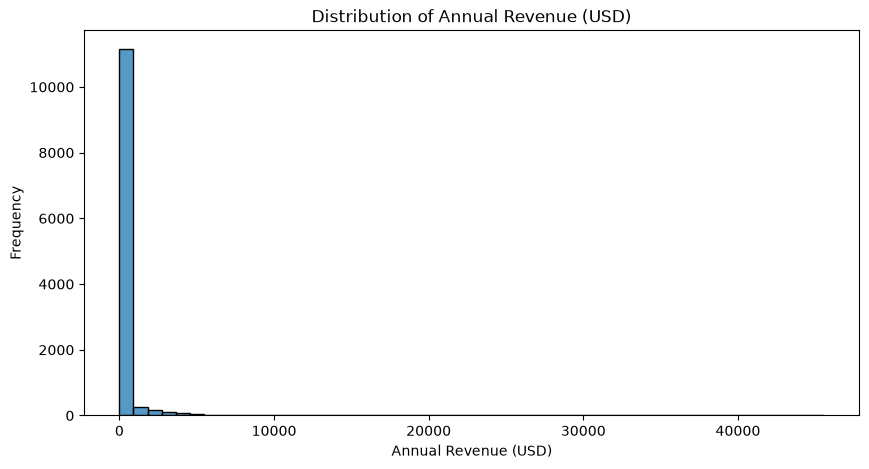

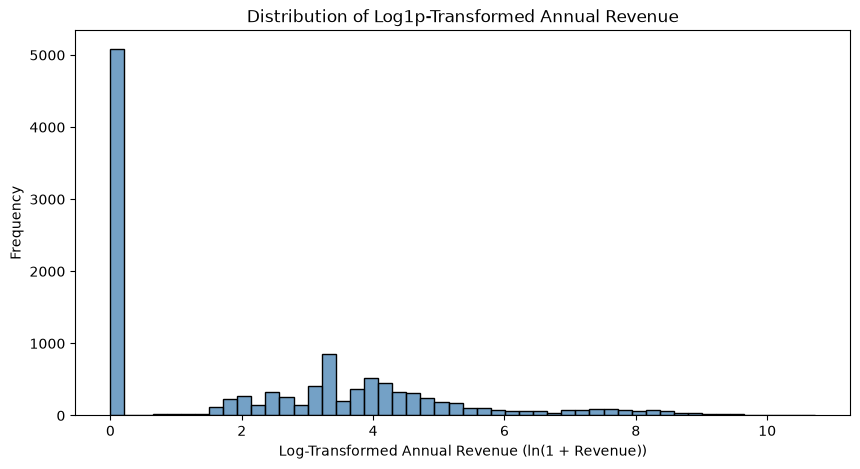

In [50]:
# Histograms comparing annual revenue distribution (USD)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="wp_revenue_USD",
    bins=50,
    kde=False
)

plt.title("Distribution of Annual Revenue (USD)")
plt.xlabel("Annual Revenue (USD)")
plt.ylabel("Frequency")
plt.show()

# Log transformed revenue histogram
# Log transformation makes it easier to see the distribution of smaller values while retaining zero revenues
log_revenue = np.log1p(df["wp_revenue_USD"])

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x=log_revenue, bins=50, kde=False, color="steelblue")

plt.title("Distribution of Log1p-Transformed Annual Revenue")
plt.xlabel("Log-Transformed Annual Revenue (ln(1 + Revenue))")
plt.ylabel("Frequency")

plt.show()

## Interpretation of revenue distribution

### Graph 1 - Distribution of Annual Revenue (USD)
### Main takeaway and modelling implications
The revenue distribution is heavily right-skewed, with most water infrastructure systems generating relatively low annual revenue. A small portion of systems generate significantly higher revenue, creating a long right tail (≈$45,562). The extreme differences in revenue could affect model performance since MSE heavily penalizes large prediction errors.

### Graph 2 - Distribution of Log1p-Transformed Annual Revenue
### Main takeaway and modelling implications
The logarithmic transformation was used to better understand the distribution through compressing large revenue values into smaller values. A prominent spike remains at zero, reflecting how 5,084 observations (42.5%) recorded no annual revenue. These zero revenue observations represent a substantial part of the dataset and should not automatically be removed.

## 3.2 Revenue Comparison by Infrastructure Type

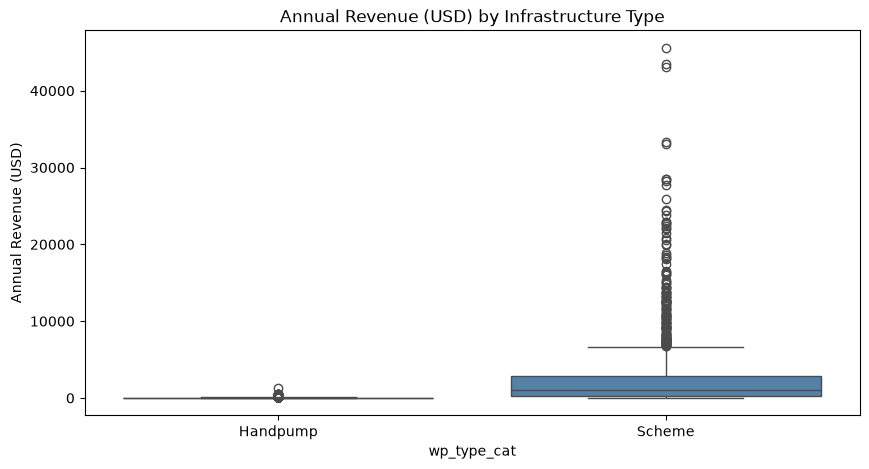

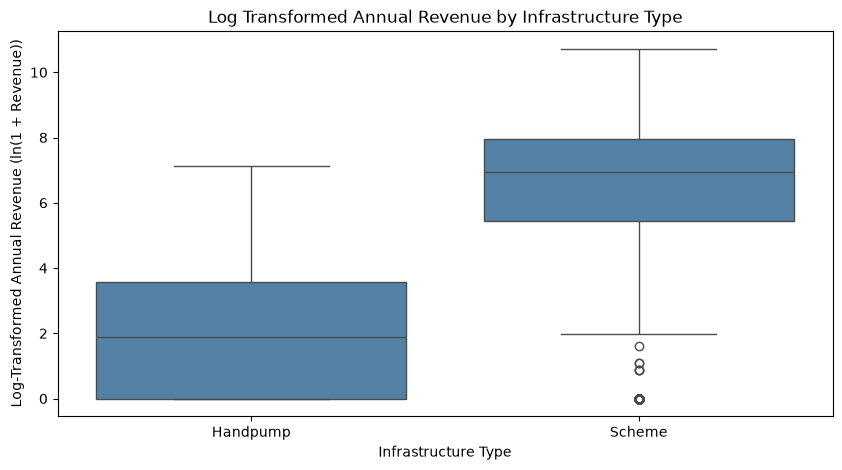

In [51]:
# Box plots comparing the revenue distributions (USD) of the two infrastructure types

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="wp_type_cat", y="wp_revenue_USD", color="steelblue")

plt.title("Annual Revenue (USD) by Infrastructure Type")
plt.ylabel("Annual Revenue (USD)")

plt.show()

# Log transformed boxplot

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="wp_type_cat", y=log_revenue, color="steelblue")

plt.title("Log Transformed Annual Revenue by Infrastructure Type")
plt.xlabel("Infrastructure Type")
plt.ylabel("Log-Transformed Annual Revenue (ln(1 + Revenue))")

plt.show()

## Interpretation of boxplots

### Graph 1 - Distribution of Annual Revenue (USD) by Infrastructure Type
### Main takeaway and modelling implications
Water schemes generate significantly higher annual revenue than handpumps. Schemes also have a greater spread in revenue with several outliers reaching ≈$45,562. The difference in revenue scale indicates that infrastructure type (wp_type_cat) is an important variable to consider when predicting annual revenue.


### Graph 2 - Distribution of Log1p-Transformed Annual Revenue by Infrastructure Type
### Main takeaway and modelling implications
Water schemes have a noticeably higher median revenue (**\$1,028**) than hand pumps (**\$5.57**). The lower quartile of handpump revenue is zero, reflecting a significant number of handpumps that generate no revenue. The observation encourages the evaluation of model performance separately for handpumps and schemes, since overall MSE may be dominated by the much larger scheme revenue, if handled together.


## 3.3 Correlation Heatmap

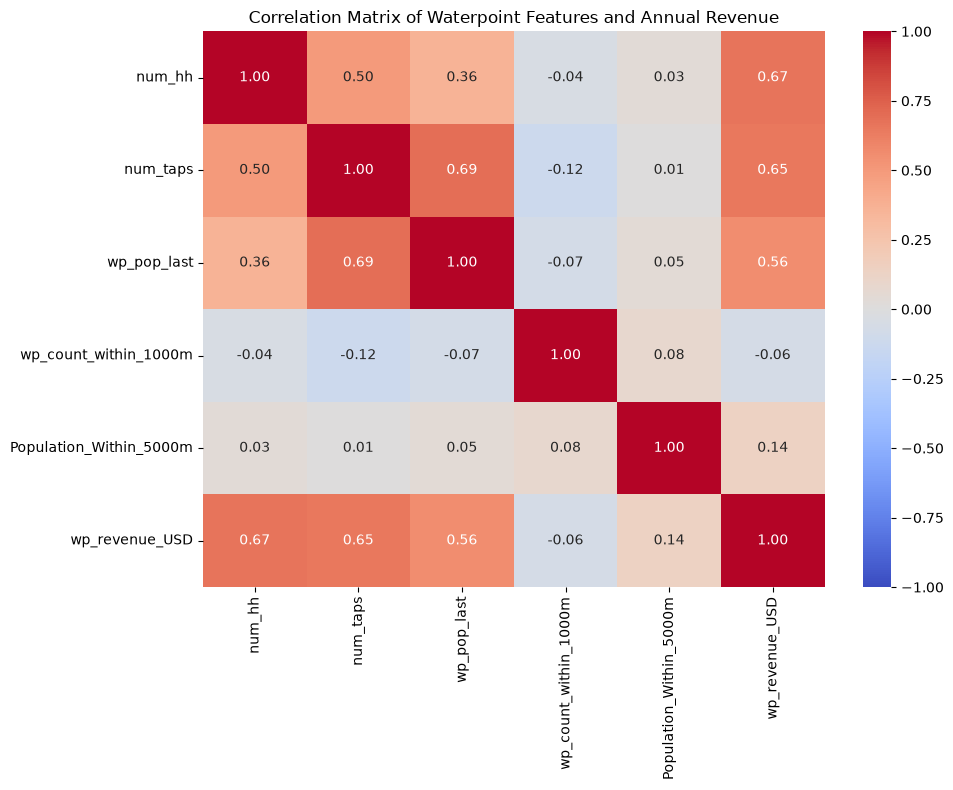

In [52]:
# Correlation heatmap of numerical predictors and the revenue target

cols = [
    "num_hh",
    "num_taps",
    "wp_pop_last",
    "wp_count_within_1000m",
    "Population_Within_5000m",
    "wp_revenue_USD",
]

# Calculation of the correlation matrix
corr_matrix = df[cols].corr()

# Plotting the heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,  # Display correlation values inside each cell
    fmt=".2f",  # Round numbers to 2 decimal places for readability
    cmap="coolwarm",  # Diverging color scheme (blue = negative, red = positive)
    vmin=-1,  # Anchor color scale minimum at -1
    vmax=1,  # Anchor color scale maximum at 1
    center=0,  # Set neutral color midpoint at 0
)

plt.title("Correlation Matrix of Waterpoint Features and Annual Revenue")
plt.tight_layout()

plt.show()

## Interpretation of correlation map
The number of households (num_hh), number of taps (num_taps), and population served (wp_pop_last) show the strongest positive relationships with annual revenue. This suggests that larger water supply systems serving more households and people tend to generate higher revenue, and that more taps tend to serve larger populations indicating potential multicollinearity. Households, taps, and population served are promising numerical predictors, whereas the weaker predictors shall initially be retained because they may capture nonlinear relationships that Decision Tree and Random Forest models can exploit.

## 3.4 Scatterplot (Before Model Training)

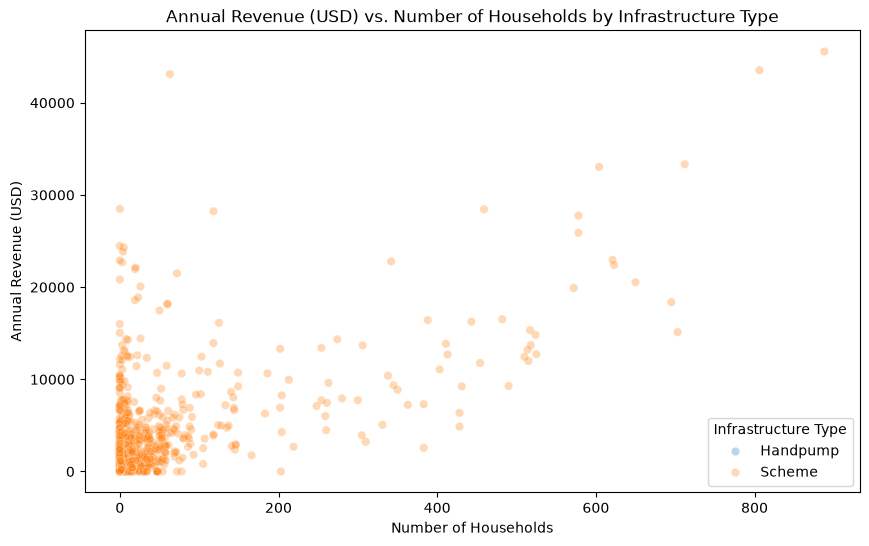

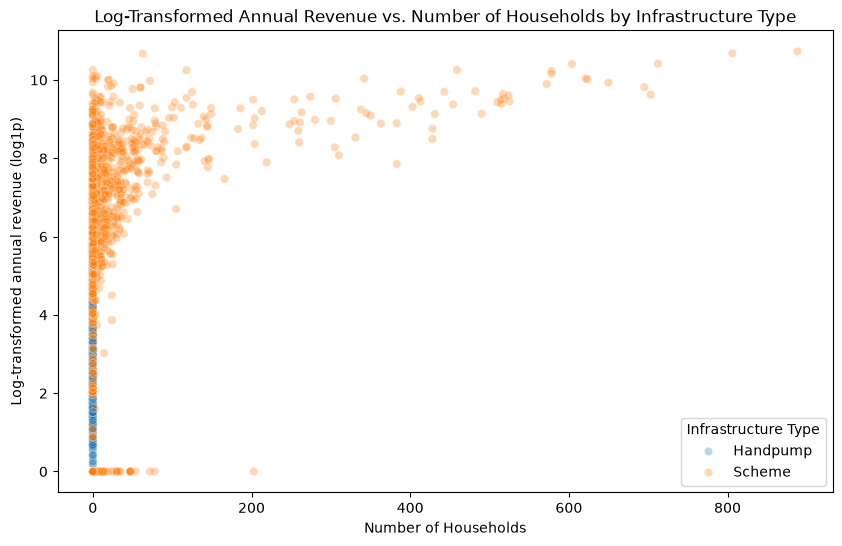

In [53]:
# Scatterplot of the most strongly correlated eligible numerical predictors against revenue

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="num_hh", y="wp_revenue_USD", hue="wp_type_cat", alpha=0.3)

plt.title("Annual Revenue (USD) vs. Number of Households by Infrastructure Type")
plt.xlabel("Number of Households")
plt.ylabel("Annual Revenue (USD)")
plt.legend(title="Infrastructure Type")

plt.show()

# Log transformed scatter plot

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="num_hh", y=log_revenue, hue="wp_type_cat", alpha=0.3)

plt.title("Log-Transformed Annual Revenue vs. Number of Households by Infrastructure Type")
plt.xlabel("Number of Households")
plt.ylabel("Log-transformed annual revenue (log1p)")
plt.legend(title="Infrastructure Type")

plt.show()



## Interpretation of scatter plot (before training)
The plot shows a general positive relationship between the number of households and annual revenue. Handpump observations remain concentrated at low household counts and revenue levels, while schemes are more widely spread across higher household counts and higher revenues. Many observations are clustered at very low household counts, especially near zero, which suggests that the dataset contains many small-scale systems, and that the relationship between households and revenue is not perfectly linear across the full range.

## 4 Data Preparation and Feature Selection

### 4.1 Feature Selection

In [54]:
# Definition of the eight selected predictor columns
predictors = [
    'wp_type_cat',
    'wp_revenue_model',
    'volume_method',
    'num_hh',
    'num_taps',
    'wp_pop_last',
    'wp_count_within_1000m',
    'Population_Within_5000m'
]

# Definition of the target variable separately
target = 'wp_revenue_USD'

# Creation of new dataframe only containing the nine columns
model_df = df[predictors + [target]].copy()

# Shape and column verification of the new data
print("New DataFrame shape:", model_df.shape)
model_df.head()

New DataFrame shape: (11957, 9)


,wp_type_cat,wp_revenue_model,volume_method,num_hh,num_taps,wp_pop_last,wp_count_within_1000m,Population_Within_5000m,wp_revenue_USD
0,Handpump,waterpoint,estimated,0,0,540,2,16765.475450,0.00
1,Handpump,waterpoint,NaN,0,0,275,0,6819.277203,105.84
2,Handpump,waterpoint,NaN,0,0,185,0,3808.431144,227.53
3,Handpump,waterpoint,NaN,0,0,200,0,5872.281555,12.96
4,Handpump,waterpoint,NaN,0,0,180,0,11283.372050,92.74


## Justification of feature exclusions

| Excluded columns | Reason |
| :--- | :--- |
| lat, lon | Anonymized placeholders (privacy/contractual reasons) |
| month_1 – month_12 | All non-missing values are zero |
| num_scheme_tanks | Approximately 70% missing |
| num_kiosks | Significant missingness and not essential to the model |
| wp_m3 | Uncertain whether actual water volume is available at prediction time |
| country_name | Encoded country labels without a verified mapping for app users |
| quarters_used | Unclear reporting-period information |
| year | The model estimates revenue from infrastructure types rather than forecasting future years |
| other population and waterpoint radius columns | Risk of introducing redundant information and calculations |

## 4.2 Missing value handling

In [55]:
# Calculating missing value counts per column
missing_count = model_df.isna().sum()

# Calculating percentage of missing values
missing_percent = (missing_count / len(model_df)) * 100

# Combining into a three-column summary table
missing_summary = pd.DataFrame({
    'Column': model_df.columns,
    'Missing Count': missing_count.values,
    'Missing Percentage (%)': missing_percent.values.round(2)
})

# Sorting the table from highest to lowest in terms of missingness
missing_summary = missing_summary.sort_values(by='Missing Count', ascending=False).reset_index(drop=True)
display(missing_summary)

,Column,Missing Count,Missing Percentage (%)
0,volume_method,3886,32.50
1,wp_revenue_model,432,3.61
2,Population_Within_5000m,59,0.49
3,wp_type_cat,0,0.00
4,num_hh,0,0.00
5,num_taps,0,0.00
6,wp_pop_last,0,0.00
7,wp_count_within_1000m,0,0.00
8,wp_revenue_USD,0,0.00


## Missing value handling strategy

| Feature | Handling strategy | Justification |
| :--- | :--- | :--- |
| wp_revenue_model | Replacing missing values with Unknown | Avoids assuming a particular payment model |
| volume_method | Replacing missing values with Unknown | Preserves observations without assuming a measurement method |
| Population_Within_5000m | Median imputation | Very few missing values; median less sensitive to extreme values |

## Interpretation of missing value handling
- Only three of the eight selected predictors contain missing values
- volume_method has the highest missingness at 32.5%, so dropping incomplete rows would result in significant data loss
- Using an unknown category for categorical values and median imputation for numerical values allows more observations to be retained without making unnecessary assumptions

## 4.3 Definition of predictors and target

In [56]:
# Assigning the eight predictor columns to X (DataFrame)
X = model_df[predictors]

# Assigning the single target column to y (Series)
y = model_df[target]

# Defining the list of the five numerical feature names
numerical_features = [
    'num_hh',
    'num_taps',
    'wp_pop_last',
    'wp_count_within_1000m',
    'Population_Within_5000m'
]

# Defining the list of the three categorical feature names
categorical_features = [
    'wp_type_cat',
    'wp_revenue_model',
    'volume_method'
]


# Shape verification
print("X shape:", X.shape)
print("y shape:", y.shape)

# Verifying that all 8 predictors are accounted for
assert len(numerical_features) + len(categorical_features) == len(predictors), "Feature count mismatch!"
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

X shape: (11957, 8)
y shape: (11957,)
Numerical features: 5
Categorical features: 3


## Interpretation of the feature separation
The features were separated into numerical and categorical categories since different data types require different preprocessing operations (Categories like "Handpump" cannot be standardized the same way as a numerical value like 500 people)

## 4.4 Train-test split

In [57]:
from sklearn.model_selection import train_test_split

# Splitting X and y into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Reserving raw observations before any preprocessing or model fitting
X_train, X_retraining, y_train, y_retraining = train_test_split(
    X_train,
    y_train,
    test_size=300,
    random_state=42
)

# Keeping the eight original predictors and labeled target together
retraining_batch = X_retraining.copy()
retraining_batch[target] = y_retraining

# Guarding the initial training, reserved batch, and unchanged test boundaries
assert len(X_train) == len(y_train) == 9265
assert len(retraining_batch) == 300
assert X_train.index.intersection(X_retraining.index).empty
assert X_test.index.intersection(X_retraining.index).empty
assert X_train.index.intersection(X_test.index).empty

# Calculating normalized proportions for wp_type_cat in both sets
train_props = X_train['wp_type_cat'].value_counts(normalize=True) * 100
test_props = X_test['wp_type_cat'].value_counts(normalize=True) * 100

# Displaying comparison table
distribution_check = pd.DataFrame({
    'Train Set (%)': train_props.round(2),
    'Test Set (%)': test_props.round(2)
})

# Verifying the shapes of the resulting splits
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("Reserved retraining observations:", len(retraining_batch))
display(distribution_check)

X_train shape: (9265, 8)
X_test shape: (2392, 8)
y_train shape: (9265,)
y_test shape: (2392,)
Reserved retraining observations: 300


,Train Set (%),Test Set (%)
wp_type_cat,,
Handpump,87.17,88.0
Scheme,12.83,12.0


## Main takeaways from the train-test splitting
- The original 80/20 split with random_state=42 produces 9,565 training observations and 2,392 test observations; the test set is unchanged.
- A reproducible random split reserves 300 raw, labeled observations from the training portion, leaving 9,265 observations for initial training. The reserved batch retains the eight predictors and wp_revenue_USD for a later retraining demonstration.
- Reserved observations are excluded from initial preprocessing fitting, model training, tuning, and selection. Tuning uses 7,412 training and 1,853 validation observations drawn only from the 9,265 initial training rows, with a separate preprocessor fitted on tuning-training data.
- Handpumps represent 87.17% of initial training observations and 88.00% of test observations. Both infrastructure types remain represented in both sets.

## 4.5 Preprocessing pipeline

In [58]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Filling missing numerical values using the median of the corresponding training column and carrying out standardization
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Filling missing categorical values with Unknown and using one-hot encoding to convert categories into binary numerical columns
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combining the two pipelines using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

# Fit on training data and transforming it
X_train_processed = preprocessor.fit_transform(X_train)

# Transforming testing data using parameters learned from X_train
X_test_processed = preprocessor.transform(X_test)

# Verifying that zero missing values remain in both transformed arrays
train_missing = np.isnan(X_train_processed).sum()
test_missing = np.isnan(X_test_processed).sum()

# Inspecting the transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Verifying the shapes of the processed arrays
print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)
print("Missing values in X_train_processed:", train_missing)
print("Missing values in X_test_processed:", test_missing)
print("\nTotal transformed features:", len(feature_names))
print("Feature names:\n", feature_names)

X_train_processed shape: (9265, 15)
X_test_processed shape: (2392, 15)
Missing values in X_train_processed: 0
Missing values in X_test_processed: 0

Total transformed features: 15
Feature names:
 ['num__num_hh' 'num__num_taps' 'num__wp_pop_last'
 'num__wp_count_within_1000m' 'num__Population_Within_5000m'
 'cat__wp_type_cat_Handpump' 'cat__wp_type_cat_Scheme'
 'cat__wp_revenue_model_Unknown' 'cat__wp_revenue_model_volumetric'
 'cat__wp_revenue_model_waterpoint' 'cat__volume_method_Unknown'
 'cat__volume_method_automated' 'cat__volume_method_estimated'
 'cat__volume_method_manual' 'cat__volume_method_unmeasured']


## Key takeaways from preprocessing pipeline
- The preprocessing pipeline successfully converted the eight original predictors into 15 numerical features through standardization and one-hot encoding
- Missing values were successfully handled without removing observations, resulting in no missing values either in the processed training or testing dataset
- The preprocessing components were fitted exclusively on the training data and then applied to the test data, ensuring consistent transformations.

## 5. Linear Regression Using SGDRegressor

## 5.1 Establishing a baseline

In [59]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Starting settings
sgd_baseline = SGDRegressor(
    loss="squared_error",       # loss function being minimized
    penalty="l2",               # regularization of model weights
    alpha=0.0001,               # Strengthening of regularization
    learning_rate="constant",   # Keeping the learning rate fixed
    eta0=0.001,                 # Initial learning rate
    max_iter=1000,              # Maximum number of epochs
    random_state=42,            # Reproducibility
)

# Fitting the model on the processed training data
sgd_baseline.fit(X_train_processed, y_train)

# Generating predictions on both training and testing sets
sgd_train_preds = sgd_baseline.predict(X_train_processed)
sgd_test_preds = sgd_baseline.predict(X_test_processed)

# Calculating evaluation metrics
train_mse = mean_squared_error(y_train, sgd_train_preds)
test_mse = mean_squared_error(y_test, sgd_test_preds)
test_mae = mean_absolute_error(y_test, sgd_test_preds)
test_r2 = r2_score(y_test, sgd_test_preds)

# Displaying results in table
results_df = pd.DataFrame({
    "Metric": ["Train MSE", "Test MSE", "Test MAE", "Test R²"],
    "Result": [train_mse, test_mse, test_mae, test_r2],
})

print(results_df.to_string(index=False))

   Metric       Result
Train MSE 1.397451e+06
 Test MSE 9.595744e+05
 Test MAE 3.633094e+02
  Test R² 6.948748e-01


## Takeaways from SGDRegressor baseline establishment
- The baseline achieved test MSE of approximately 959,574 and R² of 0.695, explaining about 69.5% of test-target variation relative to the mean-prediction reference.
- Test MAE is approximately $363.31 and RMSE approximately $979.58. The larger RMSE indicates that large errors contribute substantially, consistent with the skewed revenue distribution.
- These results provide the reference for evaluating learning-rate, regularization, and epoch adjustments.

## 5.2 Hyperparameter experimentation

## 5.2.1 Creation of validation subset

In [60]:
from sklearn.base import clone

# Splitting the raw training data into tuning-train (80%) and validation (20%) sets
X_tune_train, X_val, y_tune_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
)

# Creation of an unfitted copy of the existing preprocessor
tuning_preprocessor = clone(preprocessor)

# Fitting and transforming the tuning training set
X_tune_train_processed = tuning_preprocessor.fit_transform(X_tune_train)

# Transforming the validation set using the fitted tuning preprocessor
X_val_processed = tuning_preprocessor.transform(X_val)

# Verifying the shapes
print(f"X_tune_train: {X_tune_train.shape}")
print(f"X_val:        {X_val.shape}")
print(f"y_tune_train: {y_tune_train.shape}")
print(f"y_val:        {y_val.shape}")
print(f"X_tune_train_processed: {X_tune_train_processed.shape}")
print(f"X_val_processed:        {X_val_processed.shape}")


X_tune_train: (7412, 8)
X_val:        (1853, 8)
y_tune_train: (7412,)
y_val:        (1853,)
X_tune_train_processed: (7412, 15)
X_val_processed:        (1853, 15)


## 5.2.2 Experimenting with learning rates

In [61]:
# Candidate learning rates to test
learning_rates = [0.00001, 0.0001, 0.001, 0.01]
lr_n_epochs = 50

# Dictionaries to store epoch-by-epoch history and final summary results
history = {}
lr_results = []

for lr in learning_rates:
    # Initializing the model once outside the epoch loop so the weight carries over
    model = SGDRegressor(
        loss="squared_error",
        penalty="l2",
        alpha=0.0001,
        learning_rate="constant",
        eta0=lr,
        random_state=42,
    )

    lr_train_mse_history = []
    lr_val_mse_history = []

    # Looping through 50 epochs using partial_fit()
    for epoch in range(lr_n_epochs):
        model.partial_fit(X_tune_train_processed, y_tune_train)

        # Predicting and recording MSE after each epoch
        lr_train_preds = model.predict(X_tune_train_processed)
        lr_val_preds = model.predict(X_val_processed)

        lr_train_mse_history.append(mean_squared_error(y_tune_train, lr_train_preds))
        lr_val_mse_history.append(mean_squared_error(y_val, lr_val_preds))

    # Saving full learning curves for plotting later
    history[lr] = {
        "train_mse": lr_train_mse_history,
        "val_mse": lr_val_mse_history,
    }

    # Recording the final epoch metrics for comparison
    lr_results.append({
        "eta0": lr,
        "Final Train MSE (Epoch 50)": lr_train_mse_history[-1],
        "Final Val MSE (Epoch 50)": lr_val_mse_history[-1],
        "Best Val MSE": min(lr_val_mse_history),
    })

# Displaying the summary comparison table
lr_results_df = pd.DataFrame(lr_results)
print(lr_results_df.to_string(index=False))

   eta0  Final Train MSE (Epoch 50)  Final Val MSE (Epoch 50)  Best Val MSE
0.00001                1.331405e+06              1.553494e+06  1.477481e+06
0.00010                1.298550e+06              1.542462e+06  1.476215e+06
0.00100                1.303938e+06              1.463973e+06  1.463973e+06
0.01000                1.573370e+06              1.563438e+06  1.563438e+06


## Key takeaways from the experimentation with learning rates
- At the fixed 50-epoch budget and alpha=0.0001, learning rate 0.001 achieved the lowest final validation MSE, approximately 1,463,973, and is carried into regularization tuning.
- Learning rates 0.00001 and 0.0001 had higher final validation losses, approximately 1,553,494 and 1,542,462 respectively.
- Learning rate 0.01 produced the highest final training and validation losses among the tested rates. These results support 0.001 within this candidate grid and validation split, rather than establishing a universally optimal rate.

## 5.2.3 Experimenting with regularization strengths

In [62]:
# Selecting the learning rate using validation MSE at the fixed 50-epoch budget
selected_lr = float(lr_results_df.loc[lr_results_df['Final Val MSE (Epoch 50)'].idxmin(), 'eta0'])

alpha_values = [0.00001, 0.0001, 0.001, 0.01, 0.1]
alpha_n_epochs = 50

alpha_history = {}
alpha_results = []

for alpha in alpha_values:
    model = SGDRegressor(
        loss="squared_error",
        penalty="l2",
        alpha=alpha,
        learning_rate="constant",
        eta0=selected_lr,
        random_state=42,
    )
    
    alpha_train_mse_list = []
    alpha_val_mse_list = []

    for epoch in range(alpha_n_epochs):
        model.partial_fit(X_tune_train_processed, y_tune_train)

        # Generating predictions
        train_preds = model.predict(X_tune_train_processed)
        val_preds =  model.predict(X_val_processed)

        # Calculating and storing the mse
        train_mse = mean_squared_error(y_tune_train, train_preds)
        val_mse = mean_squared_error(y_val, val_preds)

        alpha_train_mse_list.append(train_mse)
        alpha_val_mse_list.append(val_mse)

    # Storing full epoch history
    alpha_history[alpha] = {"train_mse": alpha_train_mse_list, "val_mse": alpha_val_mse_list}

    # Appending only the final summary row
    alpha_results.append({
        "alpha": alpha,
        "Final Train MSE (Epoch 50)": alpha_train_mse_list[-1],
        "Final Val MSE (Epoch 50)": alpha_val_mse_list[-1],
        "Best Val MSE": min(alpha_val_mse_list),
    })

# Converting summary results into a dataframe
alpha_results_df = pd.DataFrame(alpha_results)
display(alpha_results_df)


,alpha,Final Train MSE (Epoch 50),Final Val MSE (Epoch 50),Best Val MSE
0,0.00001,1.303879e+06,1.463695e+06,1.463695e+06
1,0.00010,1.303938e+06,1.463973e+06,1.463973e+06
2,0.00100,1.304829e+06,1.466733e+06,1.466733e+06
3,0.01000,1.318474e+06,1.485405e+06,1.485405e+06
4,0.10000,1.348831e+06,1.491809e+06,1.490731e+06


## Key takeaways from the experimentation with regularization strengths
- Five regularization strengths were evaluated at the validation-selected learning rate of 0.001, with 50 epochs per model.
- Alpha=0.00001 achieved the lowest final validation MSE, approximately 1,463,695. Increasing alpha increased final training and validation losses in this experiment.
- Its validation improvement over alpha=0.0001 was only about 278 MSE units (0.02%), so the preference for weaker regularization is small on this split.

## 5.2.4 Experimenting with training epochs

In [63]:
# Selecting regularization at the chosen learning rate using epoch-50 validation MSE
selected_alpha = float(alpha_results_df.loc[alpha_results_df['Final Val MSE (Epoch 50)'].idxmin(), 'alpha'])
max_epochs = 500
checkpoint_epochs = [10, 50, 100, 200, 500]

# Model initialization
model = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    alpha=selected_alpha,
    learning_rate="constant",
    eta0=selected_lr,
    random_state=42
)

epoch_train_mse_list = []
epoch_val_mse_list = []

for epoch in range(max_epochs):
    model.partial_fit(X_tune_train_processed, y_tune_train)

    # Generating predictions
    train_preds = model.predict(X_tune_train_processed)
    val_preds = model.predict(X_val_processed)

    # Calculating and storing MSE
    train_mse = mean_squared_error(y_tune_train, train_preds)
    val_mse = mean_squared_error(y_val, val_preds)

    epoch_train_mse_list.append(train_mse)
    epoch_val_mse_list.append(val_mse)

# Extracting results at the five milestone epochs using zero-based indexing
epoch_results = []

for ep in checkpoint_epochs:
    idx = ep - 1 # Epoch 10 -> index 9
    epoch_results.append({
    "Epochs": ep,
    "Train MSE": epoch_train_mse_list[idx],
    "Val MSE": epoch_val_mse_list[idx],
    "Best Val MSE So Far": min(epoch_val_mse_list[: ep]),
})

# Displaying the summary DataFrame
epoch_results_df = pd.DataFrame(epoch_results)
display(epoch_results_df)

,Epochs,Train MSE,Val MSE,Best Val MSE So Far
0,10,1.319201e+06,1.489485e+06,1.489485e+06
1,50,1.303879e+06,1.463695e+06,1.463695e+06
2,100,1.303604e+06,1.461500e+06,1.461500e+06
3,200,1.303601e+06,1.461328e+06,1.461328e+06
4,500,1.303601e+06,1.461327e+06,1.461327e+06


## 5.3 Plotting and interpreting the training and validation MSE curves

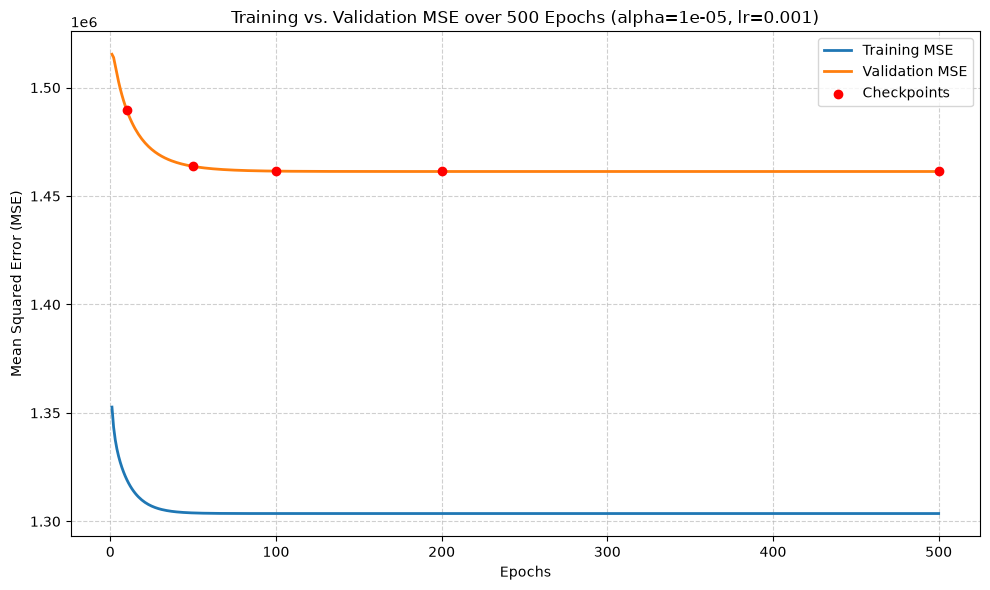

In [64]:
epochs_range = range(1, max_epochs + 1)

plt.figure(figsize=(10, 6))

plt.plot(epochs_range, epoch_train_mse_list, label="Training MSE", linewidth=2)
plt.plot(epochs_range, epoch_val_mse_list, label="Validation MSE", linewidth=2)

# Checkpoint highlighting
checkpoint_epochs = [10, 50, 100, 200, 500]
checkpoint_val_mse = [epoch_val_mse_list[ep - 1] for ep in checkpoint_epochs]

plt.scatter(
    checkpoint_epochs,
    checkpoint_val_mse,
    color="red",
    zorder=5,
    label="Checkpoints",
)

plt.title(
    f"Training vs. Validation MSE over {max_epochs} Epochs (alpha={selected_alpha},"
    f" lr={selected_lr})"
)
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## Interpretation of the loss curves
- With learning rate 0.001 and alpha=0.00001, training and validation MSE decrease rapidly initially and flatten by roughly 100-200 epochs.
- Validation MSE falls from approximately 1,489,485 at epoch 10 to 1,461,327 at epoch 500. The improvement from epoch 200 to 500 is only about one MSE unit.
- Epoch 500 has the lowest validation MSE among the five tested checkpoints and is selected automatically, although the practical gain over epoch 200 is negligible.
- Validation loss remains above training loss, but does not show a sustained upward trend as training progresses. This curve alone does not establish performance on other data splits.

## 5.4 Final Optimized SGDRegressor Training

## 5.4.1 Initializing and training the final model with partial_fit()

In [65]:
# Selecting among the existing epoch checkpoints using validation MSE only
final_n_epochs = int(epoch_results_df.loc[epoch_results_df['Val MSE'].idxmin(), 'Epochs'])
print(f'Selected SGD settings: eta0={selected_lr}, alpha={selected_alpha}, epochs={final_n_epochs}')

# Initializing fresh SGDRegressor for the full training dataset
final_sgd_model = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    alpha=selected_alpha,
    learning_rate="constant",
    eta0=selected_lr,
    random_state=42,
)

# Tracking MSE across epochs
final_train_mse_history= []
final_test_mse_history = []
for epoch in range(final_n_epochs):
    final_sgd_model.partial_fit(X_train_processed, y_train)

    # Generating training and test predictions
    sgd_train_preds = final_sgd_model.predict(X_train_processed)
    sgd_test_preds = final_sgd_model.predict(X_test_processed)

    # Calculating training and test MSE
    sgd_train_mse = mean_squared_error(y_train, sgd_train_preds)
    sgd_test_mse = mean_squared_error(y_test, sgd_test_preds)

    # Storing history
    final_train_mse_history.append(sgd_train_mse)
    final_test_mse_history.append(sgd_test_mse)

# Final epoch MSE values
print(f"Final Train MSE (Epoch {final_n_epochs}): {final_train_mse_history[-1]:,.2f}")
print(f"Final Test MSE (Epoch {final_n_epochs}):  {final_test_mse_history[-1]:,.2f}")


Selected SGD settings: eta0=0.001, alpha=1e-05, epochs=500
Final Train MSE (Epoch 500): 1,377,762.73
Final Test MSE (Epoch 500):  907,316.58


## 5.4.2 Final training and testing loss curves

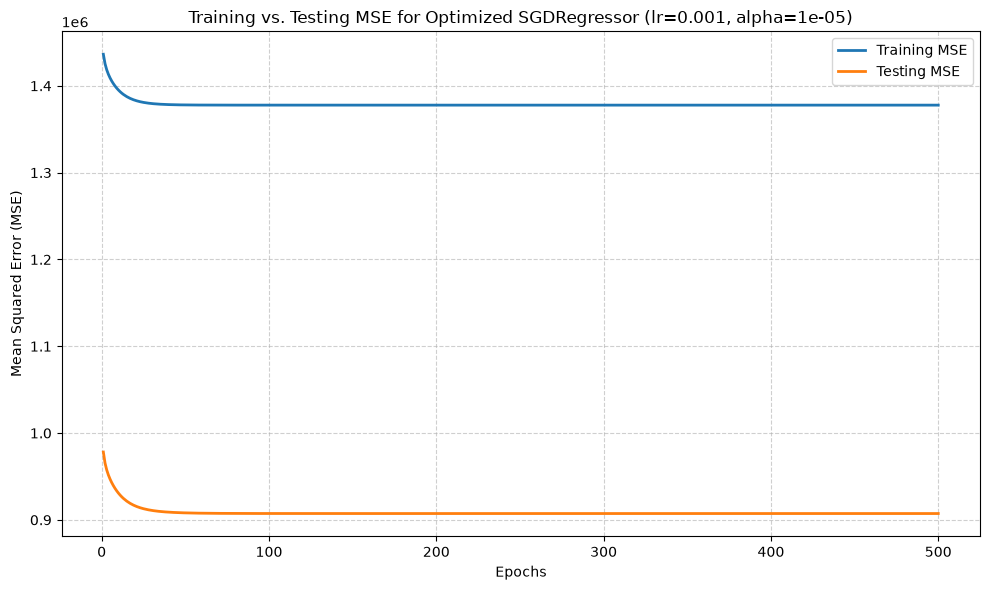

In [66]:
# x-axis ranging from epoch 1 to the final training epoch
epochs_range = range(1, final_n_epochs + 1)

plt.figure(figsize=(10, 6))

# Plotting both final loss histories
plt.plot(
    epochs_range, final_train_mse_history, label="Training MSE", linewidth=2
)
plt.plot(epochs_range, final_test_mse_history, label="Testing MSE", linewidth=2)

plt.title(
    f"Training vs. Testing MSE for Optimized SGDRegressor (lr={selected_lr},"
    f" alpha={selected_alpha})"
)
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## Interpretation of loss curve results
- Using the validation-selected settings (learning rate 0.001, alpha=0.00001, 500 epochs), full-training and test losses decline initially and stabilize.
- Final test MSE is approximately 907,317, about 5.4% below the baseline SGD MSE of 959,574; test R² is 0.7115. However, MAE increases from $363.31 to $376.00, so the improvement does not extend to every metric.
- This configuration has higher test MSE than the earlier fixed-setting run (approximately 754,399). Better validation performance did not translate into better test performance; test results are not used to reverse the validation-based choice.
- Test MSE is below training MSE. Different target distributions and difficult observations may contribute; lower test loss alone does not prove an absence of overfitting.

In [67]:
# Generating and preserving predictions from the optimized SGD model
sgd_train_preds = final_sgd_model.predict(X_train_processed)
sgd_test_preds = final_sgd_model.predict(X_test_processed)

# Reusing MSE values from the validation-selected final epoch
final_train_mse = final_train_mse_history[-1]
final_test_mse = final_test_mse_history[-1]

# Calculating additional evaluation metrics
final_test_rmse = np.sqrt(final_test_mse)
final_test_mae = mean_absolute_error(y_test, sgd_test_preds)
final_test_r2 = r2_score(y_test, sgd_test_preds)

# Calculating negative prediction count and percentage
negative_preds_count = int(np.sum(sgd_test_preds < 0))
negative_preds_pct = (negative_preds_count / len(y_test)) * 100

# Storing metrics for final model comparison
sgd_final_metrics = {
    "Model": "Optimized SGDRegressor",
    "Train MSE": final_train_mse,
    "Test MSE": final_test_mse,
    "Test RMSE": final_test_rmse,
    "Test MAE": final_test_mae,
    "Test R²": final_test_r2,
    "Negative Predictions": negative_preds_count,
    "Negative Predictions (%)": negative_preds_pct,
}

# Converting metrics into a DataFrame
sgd_results_df = pd.DataFrame([sgd_final_metrics])
display(sgd_results_df)

,Model,Train MSE,Test MSE,Test RMSE,Test MAE,Test R²,Negative Predictions,Negative Predictions (%)
0,Optimized SGDRegressor,1.377763e+06,907316.581257,952.531669,375.999932,0.711492,1351,56.479933


## 5.4.3 Analysis of Negative Predictions

In [68]:
# Creating a Boolean mask and extracting negative predictions
negative_mask = sgd_test_preds < 0
negative_values = sgd_test_preds[negative_mask]

# Calculating statistics for the negative predictions
min_neg_pred = negative_values.min() if negative_values.size > 0 else None
median_neg_pred = np.median(negative_values) if negative_values.size > 0 else np.nan
mean_neg_pred = np.mean(negative_values) if negative_values.size > 0 else np.nan

# Displaying negative prediction statistics and overall range for context
print(
    f"Total negative predictions: {len(negative_values)} out of"
    f" {len(sgd_test_preds)} ({len(negative_values) / len(sgd_test_preds):.1%})"
)
if min_neg_pred is not None:
    print(f"Minimum (most negative) prediction: {min_neg_pred:,.2f}")
else:
    print("No negative predictions.")
print(f"Median negative prediction:         {median_neg_pred:,.2f}")
print(f"Mean negative prediction:           {mean_neg_pred:,.2f}")
print(
    f"Overall prediction range:           {sgd_test_preds.min():,.2f} to"
    f" {sgd_test_preds.max():,.2f}"
)


Total negative predictions: 1351 out of 2392 (56.5%)
Minimum (most negative) prediction: -2,418.62
Median negative prediction:         -154.83
Mean negative prediction:           -164.63
Overall prediction range:           -2,418.62 to 31,655.01


In [69]:
# Creating a temporary DataFrame using .values (or .to_numpy()) to prevent index mismatch
neg_by_infra_df = pd.DataFrame({
    "wp_type_cat": X_test["wp_type_cat"].to_numpy(),
    "is_negative": sgd_test_preds < 0,
})

# Group by infrastructure type and compute count, negative count, and proportion
infra_summary = (
    neg_by_infra_df.groupby("wp_type_cat")["is_negative"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Format column names and convert proportion to percentage
infra_summary.columns = [
    "Infrastructure type",
    "Test observations",
    "Negative predictions",
    "Negative (%)",
]
infra_summary["Negative (%)"] = (infra_summary["Negative (%)"] * 100).round(2)

display(infra_summary)


,Infrastructure type,Test observations,Negative predictions,Negative (%)
0,Handpump,2105,1338,63.56
1,Scheme,287,13,4.53


## Takeaways from negative prediction analysis
- SGD produced 1,351 negative predictions out of 2,392 test observations (56.48%). They affect 63.56% of handpumps and 4.53% of schemes.
- The most negative prediction is approximately -$2,418.62. Non-negative observed revenues do not constrain an ordinary linear model's predictions.
- These outputs limit direct use for revenue estimation. Nonlinear models are evaluated next; no clipping or other prediction adjustment was applied in this notebook.

## 6. Ordinary Linear Regression

## 6.1 Training Linear Regression model

In [70]:
from sklearn.linear_model import LinearRegression

# Initializing the LinearRegression model
linear_model = LinearRegression()

# Fitting the model to the processed training data
linear_model.fit(X_train_processed, y_train)

# Generating predictions for training and testing observations
linear_train_preds = linear_model.predict(X_train_processed)
linear_test_preds = linear_model.predict(X_test_processed)

## 6.2 Evaluation of LinearRegression

In [71]:
# Metrics for LinearRegression
lin_train_mse = mean_squared_error(y_train, linear_train_preds)
lin_test_mse = mean_squared_error(y_test, linear_test_preds)
lin_test_rmse = np.sqrt(lin_test_mse)
lin_test_mae = mean_absolute_error(y_test, linear_test_preds)
lin_test_r2 = r2_score(y_test, linear_test_preds)
lin_neg_preds_count = int((linear_test_preds < 0).sum())
lin_neg_preds_pct = (lin_neg_preds_count / len(linear_test_preds)) * 100

# Storing in linear_metrics dictionary
linear_metrics = {
    "Model": "LinearRegression",
    "Train MSE": lin_train_mse,
    "Test MSE": lin_test_mse,
    "Test RMSE": lin_test_rmse,
    "Test MAE": lin_test_mae,
    "Test R²": lin_test_r2,
    "Negative Predictions": lin_neg_preds_count,
    "Negative Predictions (%)": lin_neg_preds_pct,
}

# Combining both sgd_final_metrics and linear_metrics into a comparison dataframe
comparison_df = pd.DataFrame([sgd_final_metrics, linear_metrics])


display(comparison_df)

,Model,Train MSE,Test MSE,Test RMSE,Test MAE,Test R²,Negative Predictions,Negative Predictions (%)
0,Optimized SGDRegressor,1.377763e+06,907316.581257,952.531669,375.999932,0.711492,1351,56.479933
1,LinearRegression,1.310385e+06,752315.021702,867.360952,290.164788,0.760779,1200,50.167224


## 6.3 Supplementary One-Feature Linear Regression Visualization

## 6.3.1 Fitting a supplementary 1D LinearRegression model using only num_hh

In [72]:
# Fitting a supplementary 1D LinearRegression model using only num_hh
simple_lr = LinearRegression()
simple_lr.fit(X_train[["num_hh"]], y_train)

# Extracting the slope and intercept
slope = simple_lr.coef_[0]
intercept = simple_lr.intercept_

# Generating fitted values across the observed test range of num_hh
x_range = np.linspace(X_test["num_hh"].min(), X_test["num_hh"].max(), 200)
x_grid = pd.DataFrame({"num_hh": x_range})
y_fitted = simple_lr.predict(x_grid)

## 6.3.2 Plotting test observations and supplementary 1D best-fit line

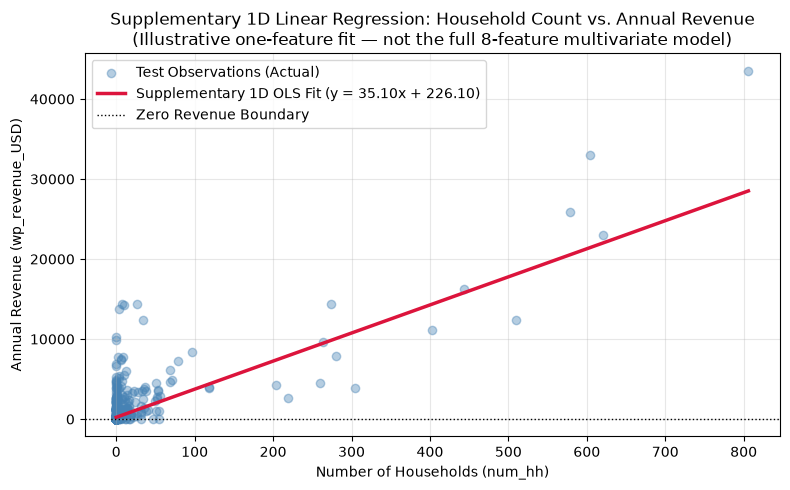

Supplementary 1D Model — Slope: 35.0951 USD per household
Supplementary 1D Model — Intercept: 226.0991 USD
Supplementary 1D Model — Test R²: 0.6437


In [73]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X_test["num_hh"],
    y_test,
    alpha=0.4,
    color="steelblue",
    label="Test Observations (Actual)",
)
plt.plot(
    x_range,
    y_fitted,
    color="crimson",
    linewidth=2.5,
    label=f"Supplementary 1D OLS Fit (y = {slope:.2f}x + {intercept:.2f})",
)
plt.axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=1,
    label="Zero Revenue Boundary",
)
plt.title(
    "Supplementary 1D Linear Regression: Household Count vs. Annual Revenue\n"
    "(Illustrative one-feature fit — not the full 8-feature multivariate model)"
)
plt.xlabel("Number of Households (num_hh)")
plt.ylabel("Annual Revenue (wp_revenue_USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Supplementary 1D Model — Slope: {slope:.4f} USD per household")
print(f"Supplementary 1D Model — Intercept: {intercept:.4f} USD")
print(
    f"Supplementary 1D Model — Test R²: {simple_lr.score(X_test[['num_hh']], y_test):.4f}"
)

## Key takeaways from the supplementary one-feature linear regression visualization
- The supplementary one-feature regression shows a positive relationship between household count and annual water-service revenue, with an estimated increase of approximately $35.10 in predicted revenue per additional household
- The model achieved an R² of approximately 0.644 on the test set, suggesting that household count alone explains a significant proportion of the observed revenue variation, although considerable prediction errors remain
- The stronger performance of the multivariate models demonstrates the value of considering additional infrastructure and service characteristics when estimating revenue

## 6.4 Model Evaluation and Comparison

- **Test MSE and R²:** LinearRegression achieved lower test MSE than validation-selected SGD (752,315 versus 907,317, approximately 17.1% lower) and higher R² (0.7608 versus 0.7115).
- **Absolute errors:** LinearRegression also achieved lower MAE ($290.16 versus $376.00) and RMSE ($867.36 versus $952.53) on this test set.
- **Negative predictions:** LinearRegression produced 1,200 negative estimates (50.17%) and SGD produced 1,351 (56.48%). Both remain problematic for a non-negative revenue target.
- **Next steps:** Nonlinear models are evaluated to investigate whether they improve prediction accuracy and produce non-negative estimates. The observed test advantage does not establish superiority across other splits.

## 7. Decision Tree Regression

## 7.1 Training baseline Decision Tree

In [74]:
from sklearn.tree import DecisionTreeRegressor

# Initializing the baseline DecisionTreeRegressor with default settings and fixed seed
baseline_dt = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
)

# Fitting the model on the processed training data
baseline_dt.fit(X_train_processed, y_train)

# Generating predictions for both training and testing
dt_baseline_train_preds = baseline_dt.predict(X_train_processed)
dt_baseline_test_preds = baseline_dt.predict(X_test_processed)

## 7.2 Evaluating the baseline model

In [75]:
# Calculating training and testing metrics
dt_train_mse = mean_squared_error(y_train, dt_baseline_train_preds)
dt_test_mse = mean_squared_error(y_test, dt_baseline_test_preds)
dt_test_rmse = np.sqrt(dt_test_mse)
dt_test_mae = mean_absolute_error(y_test, dt_baseline_test_preds)
dt_test_r2 = r2_score(y_test, dt_baseline_test_preds)

# Counting and finding percentage of negative predictions on the test set
dt_neg_preds_count = int((dt_baseline_test_preds < 0).sum())
dt_neg_preds_pct = (dt_neg_preds_count / len(dt_baseline_test_preds)) * 100

# Storing and displaying results in summary table
dt_baseline_results = pd.DataFrame([{
    "Model": "Baseline Decision Tree",
    "Train MSE": dt_train_mse,
    "Test MSE": dt_test_mse,
    "Test RMSE ($)": dt_test_rmse,
    "Test MAE ($)": dt_test_mae,
    "Test R²": dt_test_r2,
    "Negative Predictions": dt_neg_preds_count,
    "Negative Predictions (%)": dt_neg_preds_pct,
}])

display(dt_baseline_results)

,Model,Train MSE,Test MSE,Test RMSE ($),Test MAE ($),Test R²,Negative Predictions,Negative Predictions (%)
0,Baseline Decision Tree,6559.960649,641189.551871,800.743125,154.733115,0.796115,0,0.0


## 7.3 Investigating overfitting and tree complexity

## 7.3.1 Decision tree depth investigation

In [76]:
# Defining candidate max_depth values
max_depth_values = [3, 5, 10, 15, None]
depth_results = []

# Looping through each candidate depth
for depth in max_depth_values:

    # Initializing a fresh tree with the current max_depth
    dt_model = DecisionTreeRegressor(
        criterion="squared_error",
        max_depth=depth,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    )

    # Fitting only on the tuning-training set
    dt_model.fit(X_tune_train_processed, y_tune_train)

    # Generating predictions on tuning-train and validation
    dt_train_preds = dt_model.predict(X_tune_train_processed)
    dt_val_preds = dt_model.predict(X_val_processed)

    # Calculating MSE, RMSE and R²
    dt_train_mse = mean_squared_error(y_tune_train, dt_train_preds)
    dt_val_mse = mean_squared_error(y_val, dt_val_preds)
    dt_val_rmse = np.sqrt(dt_val_mse)
    dt_val_r2 = r2_score(y_val, dt_val_preds)

    # Storing results
    depth_results.append({
        "max_depth": str(depth),
        "Actual Tree Depth": dt_model.get_depth(),
        "Leaf Count": dt_model.get_n_leaves(),
        "Tune Train MSE": dt_train_mse,
        "Val MSE": dt_val_mse,
        "Val RMSE": dt_val_rmse,
        "Val R²": dt_val_r2,
    })

# Building and displaying comparison DataFrame
depth_results_df = pd.DataFrame(depth_results)
display(depth_results_df)


,max_depth,Actual Tree Depth,Leaf Count,Tune Train MSE,Val MSE,Val RMSE,Val R²
0,3,3,8,1.061484e+06,1.936082e+06,1391.431612,0.306129
1,5,5,27,7.550917e+05,1.657054e+06,1287.265934,0.406129
2,10,10,200,1.825209e+05,1.713318e+06,1308.937622,0.385965
3,15,15,877,2.563311e+04,1.660453e+06,1288.585749,0.404911
4,None,40,4590,2.260180e+03,1.737740e+06,1318.233507,0.377212


## Takeaways from decision tree depth investigation results
- Increasing depth substantially reduced training MSE, but validation MSE did not improve monotonically.
- Depth 5 achieved the lowest validation MSE among these configurations, approximately 1,657,054. Depth 15 was close at approximately 1,660,453, despite fitting training observations much more closely.
- The unrestricted tree had validation MSE of approximately 1,737,740. The existing next experiment compares depths 3 and 5 with different minimum leaf sizes.

## Training vs Validation MSE by tree depth visualization

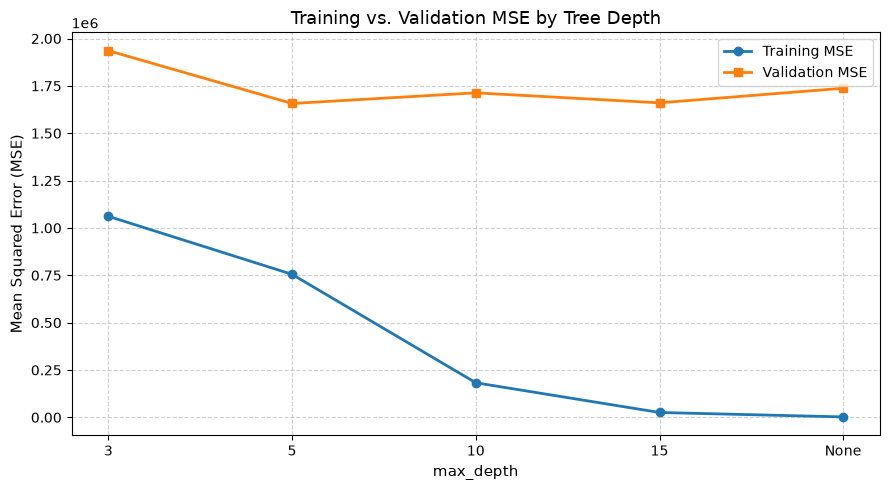

In [77]:
# Positional x-coordinates
x_positions = np.arange(len(depth_results_df))
depth_labels = depth_results_df["max_depth"].astype(str)

# Initializing the figure
plt.figure(figsize=(9, 5))

# Plotting training MSE and validation MSE
plt.plot(
    x_positions,
    depth_results_df["Tune Train MSE"],
    marker="o",
    linewidth=2,
    label="Training MSE",
)
plt.plot(
    x_positions,
    depth_results_df["Val MSE"],
    marker="s",
    linewidth=2,
    label="Validation MSE",
)

# Replacing numeric positions with actual max_depth labels including None
plt.xticks(ticks=x_positions, labels=depth_labels)

plt.title("Training vs. Validation MSE by Tree Depth", fontsize=13)
plt.xlabel("max_depth", fontsize=11)
plt.ylabel("Mean Squared Error (MSE)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()

plt.show()

## Key takeaways from tree depth visualization
- Training MSE decreases strongly as depth increases.
- Validation MSE drops from depth 3 to depth 5, then fluctuates for deeper trees; it does not consistently worsen with every increase in depth.
- Depth 5 provides the lowest validation loss in this experiment. Much lower training loss in deeper trees does not translate into lower validation loss, supporting investigation of complexity restrictions.

## 7.3.3 Decision tree leaf-size experimentation

In [78]:
# Defining the candidate hyperparameter grids
max_depth_candidates = [3, 5]
min_samples_leaf_candidates = [1, 5, 10, 20]

leaf_results = []

# Nested loop over max_depth and min_samples_leaf (giving 8 total combinations / 8 separate decision tree models)
for depth in max_depth_candidates:
    for min_leaf in min_samples_leaf_candidates:
        # Initializing a fresh DecisionTreeRegressor
        dt_tune_model = DecisionTreeRegressor(
            criterion="squared_error",
            max_depth=depth,
            min_samples_split=2,
            min_samples_leaf=min_leaf,
            random_state=42,     
        )

        # Fitting only on tuning-training data
        dt_tune_model.fit(X_tune_train_processed, y_tune_train)

        # Generating training and validation predictions
        dt_tune_train_preds = dt_tune_model.predict(X_tune_train_processed)
        dt_tune_val_preds = dt_tune_model.predict(X_val_processed)

        # Calculating training and validation MSE
        dt_tune_train_mse = mean_squared_error(y_tune_train, dt_tune_train_preds)
        dt_tune_val_mse = mean_squared_error(y_val, dt_tune_val_preds)
        dt_tune_val_rmse = np.sqrt(dt_tune_val_mse)
        dt_tune_val_r2 = r2_score(y_val, dt_tune_val_preds)

        # Storing evaluation metrics
        leaf_results.append({
            "max_depth": depth,
            "min_samples_leaf": min_leaf,
            "Actual Depth": dt_tune_model.get_depth(),
            "Leaf Count": dt_tune_model.get_n_leaves(),
            "Tune Train MSE": dt_tune_train_mse,
            "Tune Val MSE": dt_tune_val_mse,
            "Tune Val RMSE ($)": dt_tune_val_rmse,
            "Tune Val R²": dt_tune_val_r2,
        })

# Converting to dataframe and sorting by dt_tune_val_mse ascending
leaf_results_df = (
    pd.DataFrame(leaf_results).sort_values(by="Tune Val MSE", ascending=True).reset_index(drop=True)
)
display(leaf_results_df)

,max_depth,min_samples_leaf,Actual Depth,Leaf Count,Tune Train MSE,Tune Val MSE,Tune Val RMSE ($),Tune Val R²
0,5,5,5,20,9.014632e+05,1.254674e+06,1120.122423,0.550338
1,3,5,3,8,1.145985e+06,1.324062e+06,1150.678786,0.525470
2,5,10,5,18,1.143663e+06,1.337399e+06,1156.459543,0.520690
3,3,10,3,7,1.347551e+06,1.417000e+06,1190.377958,0.492162
4,5,1,5,27,7.550917e+05,1.657054e+06,1287.265934,0.406129
5,5,20,5,17,1.339699e+06,1.755102e+06,1324.802554,0.370990
6,3,20,3,7,1.482578e+06,1.911548e+06,1382.587375,0.314921
7,3,1,3,8,1.061484e+06,1.936082e+06,1391.431612,0.306129


## Takeaways from decision tree leaf-size experimentation
- Eight combinations of depth and minimum leaf size were evaluated.
- max_depth=5 and min_samples_leaf=5 achieved the lowest validation MSE, approximately 1,254,674, with validation R² of 0.5503. These parameters are selected automatically for final training.
- A minimum leaf size of five improved validation performance at both tested depths compared with one. Larger leaf sizes did not improve on the winning configuration, illustrating the trade-off between flexibility and simplification.

## 7.4 Final Optimized Decision Tree

In [79]:
best_dt_params = leaf_results_df.loc[leaf_results_df['Tune Val MSE'].idxmin()]

# Initializing the final optimized Decision Tree with winning hyperparameters
final_dt_model = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=int(best_dt_params['max_depth']),
    min_samples_leaf=int(best_dt_params['min_samples_leaf']),
    min_samples_split=2,
    random_state=42,
)

# Fitting on the Full training dataset
final_dt_model.fit(X_train_processed, y_train)

# Generating predictions on both the full training and test sets
dt_final_train_preds = final_dt_model.predict(X_train_processed)
dt_final_test_preds = final_dt_model.predict(X_test_processed)

# Calculating all standard evaluation metrics
dt_final_train_mse = mean_squared_error(y_train, dt_final_train_preds)
dt_final_test_mse = mean_squared_error(y_test, dt_final_test_preds)
dt_final_test_rmse = np.sqrt(dt_final_test_mse)
dt_final_test_mae = mean_absolute_error(y_test, dt_final_test_preds)
dt_final_test_r2 = r2_score(y_test, dt_final_test_preds)

dt_final_neg_count = int((dt_final_test_preds < 0).sum())
dt_final_neg_pct = (dt_final_neg_count / len(dt_final_test_preds)) * 100

# Storing metrics 
dt_final_metrics = {
    "Model": "Optimized Decision Tree",
    "Train MSE": dt_final_train_mse,
    "Test MSE": dt_final_test_mse,
    "Test RMSE": dt_final_test_rmse,
    "Test MAE": dt_final_test_mae,
    "Test R²": dt_final_test_r2,
    "Negative Predictions": dt_final_neg_count,
    "Negative Predictions (%)": dt_final_neg_pct,
}

# Displaying the dataframe
dt_final_results_df = pd.DataFrame([dt_final_metrics])
display(dt_final_results_df)

,Model,Train MSE,Test MSE,Test RMSE,Test MAE,Test R²,Negative Predictions,Negative Predictions (%)
0,Optimized Decision Tree,878416.299271,919036.809161,958.664075,201.929411,0.707765,0,0.0


## Takeaways from final optimized decision tree
- Hyperparameter tuning selected a depth 5-Decision Tree with a minimum of five samples per leaf based on validation MSE
- Despite reducing tree complexity and producing no negative predictions, the tuned model achieved a higher test MSE than the unrestricted baseline, indicating that its performance did not generalize as well to the final test
- The results highlight the trade-off between model complexity and generalization, particularly when working with a highly skewed revenue dataset

## 8. Random Forest Regression

## 8.1 Training baseline Random Forest

In [80]:
from sklearn.ensemble import RandomForestRegressor

# Initializing the baseline Random Forest Model
baseline_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1,
)

# Fitting the model on the training dataset
baseline_rf.fit(X_train_processed, y_train)

# Generating training and testing predictions
rf_baseline_train_preds = baseline_rf.predict(X_train_processed)
rf_baseline_test_preds = baseline_rf.predict(X_test_processed)

# Evaluation of performance metrics
rf_train_mse = mean_squared_error(y_train, rf_baseline_train_preds)
rf_test_mse = mean_squared_error(y_test, rf_baseline_test_preds)
rf_train_r2 = r2_score(y_train, rf_baseline_train_preds)
rf_test_r2 = r2_score(y_test, rf_baseline_test_preds)

print(f"Baseline RF Train MSE: {rf_train_mse:,.2f} | R2: {rf_train_r2:.4f}")
print(f"Baseline RF Test MSE:  {rf_test_mse:,.2f} | R2: {rf_test_r2:.4f}")

Baseline RF Train MSE: 107,995.67 | R2: 0.9675
Baseline RF Test MSE:  399,995.07 | R2: 0.8728


## 8.2 Evaluating the baseline random forest model

In [81]:
# Calculating the evaluation metrics
rf_baseline_train_mse = mean_squared_error(y_train, rf_baseline_train_preds)
rf_baseline_test_mse = mean_squared_error(y_test, rf_baseline_test_preds)
rf_baseline_rmse = np.sqrt(rf_baseline_test_mse)
rf_baseline_mae = mean_absolute_error(y_test, rf_baseline_test_preds)
rf_baseline_r2 = r2_score(y_test, rf_baseline_test_preds)
rf_baseline_neg_preds = int(np.sum(rf_baseline_test_preds < 0))

# Storing the results
rf_baseline_metrics = {
    "Model": "Baseline Random Forest",
    "Train MSE": rf_baseline_train_mse,
    "Test MSE": rf_baseline_test_mse,
    "RMSE": rf_baseline_rmse,
    "MAE": rf_baseline_mae,
    "R2": rf_baseline_r2,
    "Negative Predictions": rf_baseline_neg_preds,
}

# Displaying the metrics
display(pd.DataFrame([rf_baseline_metrics]))


,Model,Train MSE,Test MSE,RMSE,MAE,R2,Negative Predictions
0,Baseline Random Forest,107995.673473,399995.067549,632.451633,135.108949,0.87281,0


## Key takeaways from baseline random forest
- The baseline Random Forest achieved test MSE of approximately 399,995, R² of 0.8728, RMSE of $632.45, and MAE of $135.11, outperforming the preceding models on this test set.
- Training MSE was approximately 107,996, leaving a substantial training-test gap. The test-to-training error ratio is smaller than for the unrestricted Decision Tree, consistent with a benefit from ensemble averaging on this split.
- No negative revenue predictions were produced. Non-negative predictions are appropriate for this target, but do not guarantee accurate estimates.

## 8.3 Random Forest Hyperparameter tuning

In [82]:
# Defining the candidate hyperparameter values
rf_n_estimators_values = [100, 200]
rf_max_depth_values = [None, 10, 20]
rf_min_samples_leaf_values = [1, 5]

# Initializing empty results list
rf_tuning_results = []

# Three nested loops over all hyperparameter combinations
for n_est in rf_n_estimators_values:
    for depth in rf_max_depth_values:
        for min_leaf in rf_min_samples_leaf_values:

            # Initializing the fresh Random Forest model
            rf_tune_model = RandomForestRegressor(
                n_estimators=n_est,
                max_depth=depth,
                min_samples_leaf=min_leaf,
                random_state=42,
                n_jobs=-1,
            )

            # Fitting using tuning-training observations
            rf_tune_model.fit(X_tune_train_processed, y_tune_train)

            # Generating predictions
            rf_tune_train_preds = rf_tune_model.predict(X_tune_train_processed)
            rf_tune_val_preds = rf_tune_model.predict(X_val_processed)

            # Calculating evaluation metrics
            rf_tune_train_mse = mean_squared_error(y_tune_train, rf_tune_train_preds)
            rf_tune_val_mse = mean_squared_error(y_val, rf_tune_val_preds)
            rf_tune_val_rmse = np.sqrt(rf_tune_val_mse)
            rf_tune_val_r2 = r2_score(y_val, rf_tune_val_preds)

            # Storing results
            rf_tuning_results.append({
                "n_estimators": n_est,
                "max_depth": depth,
                "min_samples_leaf": min_leaf,
                "Tune Train MSE": rf_tune_train_mse,
                "Tune Val MSE": rf_tune_val_mse,
                "Tune Val RMSE": rf_tune_val_rmse,
                "Tune Val R²": rf_tune_val_r2,
            })

# Creating dataframe, sorting by validation MSE ascending
rf_tuning_results_df = pd.DataFrame(rf_tuning_results).sort_values(by="Tune Val MSE", ascending=True)
display(rf_tuning_results_df)


,n_estimators,max_depth,min_samples_leaf,Tune Train MSE,Tune Val MSE,Tune Val RMSE,Tune Val R²
5,100,20.0,5,542050.238262,1.067041e+06,1032.976830,0.617584
1,100,NaN,5,541817.694812,1.067258e+06,1033.081974,0.617506
7,200,NaN,5,538628.763374,1.073108e+06,1035.909392,0.615409
11,200,20.0,5,538662.334167,1.073267e+06,1035.986033,0.615352
3,100,10.0,5,574320.287953,1.080047e+06,1039.253215,0.612922
9,200,10.0,5,571444.729745,1.085827e+06,1042.030414,0.610851
0,100,NaN,1,105075.301465,1.110985e+06,1054.032930,0.601834
6,200,NaN,1,99233.135003,1.116549e+06,1056.668824,0.599841
10,200,20.0,1,99977.890223,1.121009e+06,1058.777155,0.598242
4,100,20.0,1,107138.910737,1.124661e+06,1060.500306,0.596933


## Takeaway from random forest hyperparameter tuning
- Twelve configurations were evaluated using validation MSE.
- The winner has 100 estimators, maximum depth 20, and minimum leaf size 5, with validation MSE approximately 1,067,041 and R² of 0.6176. Final training now uses these parameters automatically.
- All six configurations with minimum leaf size five outperform those with leaf size one on this validation split. Increasing estimators to 200 does not consistently help.
- The unrestricted-depth, 100-tree, leaf-size-five configuration is close to the winner (validation MSE approximately 1,067,258), so the depth preference is marginal.

## 8.4 Final Optimized Random Forest

In [83]:
best_rf_params = rf_tuning_results_df.loc[rf_tuning_results_df['Tune Val MSE'].idxmin()]
selected_rf_depth = None if pd.isna(best_rf_params['max_depth']) else int(best_rf_params['max_depth'])

# Initializing the final model using the winning hyperparameters
final_rf_model = RandomForestRegressor(
    n_estimators=int(best_rf_params['n_estimators']),
    max_depth=selected_rf_depth,
    min_samples_leaf=int(best_rf_params['min_samples_leaf']),
    random_state=42,
    n_jobs=-1
)

# Training on the full training dataset
final_rf_model.fit(X_train_processed, y_train)

# Generating fresh predictions for both training and testing sets
rf_final_train_preds = final_rf_model.predict(X_train_processed)
rf_final_test_preds = final_rf_model.predict(X_test_processed)

# Calculating evaluation metrics
rf_final_train_mse = mean_squared_error(y_train, rf_final_train_preds)
rf_final_test_mse = mean_squared_error(y_test, rf_final_test_preds)
rf_final_test_rmse = np.sqrt(rf_final_test_mse)
rf_final_test_mae = mean_absolute_error(y_test, rf_final_test_preds)
rf_final_test_r2 = r2_score(y_test, rf_final_test_preds)

rf_final_neg_count = int((rf_final_test_preds < 0).sum())
rf_final_neg_pct = (rf_final_neg_count / len(rf_final_test_preds)) * 100

# Storing the results
rf_final_metrics = {
    "Model": "Tuned Random Forest",
    "Train MSE": rf_final_train_mse,
    "Test MSE": rf_final_test_mse,
    "Test RMSE": rf_final_test_rmse,
    "Test MAE": rf_final_test_mae,
    "Test R²": rf_final_test_r2,
    "Negative Predictions": rf_final_neg_count,
    "Negative Predictions (%)": rf_final_neg_pct,
}

display(pd.DataFrame([rf_final_metrics]))

,Model,Train MSE,Test MSE,Test RMSE,Test MAE,Test R²,Negative Predictions,Negative Predictions (%)
0,Tuned Random Forest,525787.685165,527271.688829,726.134759,149.771771,0.832338,0,0.0


## Key takeaways from the final optimized random forest
- The validation-selected forest achieved test MSE approximately 527,272, R² of 0.8323, RMSE of $726.13, and MAE of $149.77, with zero negative predictions.
- It performs worse on test MSE than the baseline forest (399,995), by approximately 31.8%, despite winning the validation search. RMSE and MAE are also higher. Validation tuning did not improve test performance in this run.
- Training MSE (525,788) and test MSE are close. The smaller gap accompanies higher training and test error than the baseline; a smaller gap alone does not mean better predictions.
- It still has lower test MSE than the unrestricted Decision Tree and all three other models in the final four-model comparison.

## 9. Final Model Comparison, Selection and Saving

## 9.1 Final Model Comparison

In [84]:
# Verify that all four dictionaries share identical keys before combining
print("SGD keys:   ", list(sgd_final_metrics.keys()))
print("Linear keys:", list(linear_metrics.keys()))
print("DT keys:    ", list(dt_final_metrics.keys()))
print("RF keys:    ", list(rf_final_metrics.keys()))

SGD keys:    ['Model', 'Train MSE', 'Test MSE', 'Test RMSE', 'Test MAE', 'Test R²', 'Negative Predictions', 'Negative Predictions (%)']
Linear keys: ['Model', 'Train MSE', 'Test MSE', 'Test RMSE', 'Test MAE', 'Test R²', 'Negative Predictions', 'Negative Predictions (%)']
DT keys:     ['Model', 'Train MSE', 'Test MSE', 'Test RMSE', 'Test MAE', 'Test R²', 'Negative Predictions', 'Negative Predictions (%)']
RF keys:     ['Model', 'Train MSE', 'Test MSE', 'Test RMSE', 'Test MAE', 'Test R²', 'Negative Predictions', 'Negative Predictions (%)']


In [85]:
# Combining all four model dictionaries into a single Dataframe
final_comparison_df = pd.DataFrame(
    [sgd_final_metrics, linear_metrics, dt_final_metrics, rf_final_metrics]
)

# Sorting by TEST MSE in ascending order (Lowest error)
final_comparison_df = final_comparison_df.sort_values(
    by="Test MSE", ascending=True
).reset_index(drop=True)

# Displaying the final comparison table
display(final_comparison_df)

,Model,Train MSE,Test MSE,Test RMSE,Test MAE,Test R²,Negative Predictions,Negative Predictions (%)
0,Tuned Random Forest,5.257877e+05,527271.688829,726.134759,149.771771,0.832338,0,0.000000
1,LinearRegression,1.310385e+06,752315.021702,867.360952,290.164788,0.760779,1200,50.167224
2,Optimized SGDRegressor,1.377763e+06,907316.581257,952.531669,375.999932,0.711492,1351,56.479933
3,Optimized Decision Tree,8.784163e+05,919036.809161,958.664075,201.929411,0.707765,0,0.000000


## Visualization of the model comparison

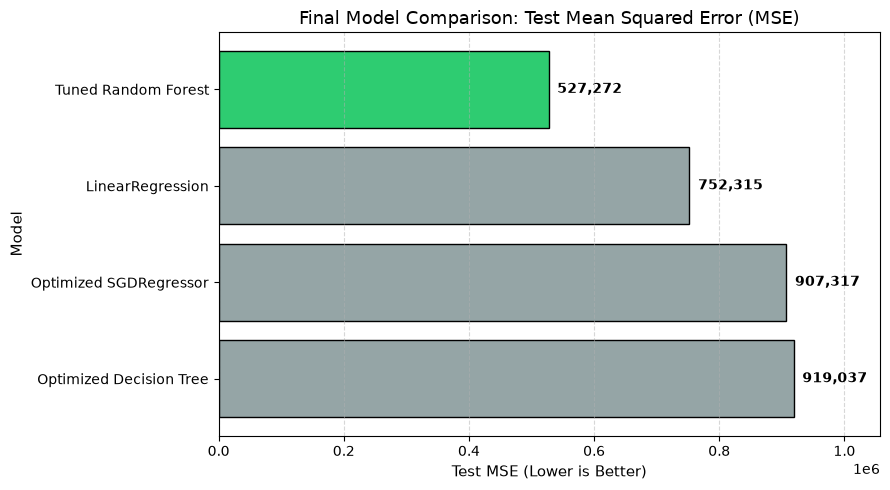

In [86]:
# Creating a copy sorted descending so the best model (Lowest MSE) appears at the top
plot_df = final_comparison_df.sort_values(by="Test MSE", ascending=False)

# Initializing the figure
plt.figure(figsize=(9, 5))

# Highlighting the winning model
colors = ["#95a5a6"] * (len(plot_df) - 1) + ["#2ecc71"]

bars = plt.barh(
    plot_df["Model"], plot_df["Test MSE"], color=colors, edgecolor="black"
)

# Adding Test MSE data labels to the end of each bar
for bar in bars:
  width = bar.get_width()
  plt.text(
      width + (plot_df["Test MSE"].max() * 0.015),
      bar.get_y() + bar.get_height() / 2,
      f"{width:,.0f}",
      va="center",
      ha="left",
      fontsize=10,
      fontweight="bold",
  )

# Label formatting
plt.xlabel("Test MSE (Lower is Better)", fontsize=11)
plt.ylabel("Model", fontsize=11)
plt.title("Final Model Comparison: Test Mean Squared Error (MSE)", fontsize=13)
plt.xlim(
    0, plot_df["Test MSE"].max() * 1.15
)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

## Key takeaways from final model comparison

| Finding | Evidence |
| :--- | :--- |
| Lowest test MSE among the four final models | Validation-selected Random Forest: 527,272 |
| Highest test R² among those models | Random Forest: 0.8323 |
| Lowest test MAE among those models | Random Forest: $149.77 |
| Non-negative predictions | Both final tree models produce zero negative predictions |
| Important comparison outside this table | Baseline Random Forest has lower test MSE: 399,995 |

**Selection:** Random Forest has the lowest validation MSE in the reported searches and leads the final four-model test comparison. Its selected configuration is 100 trees, depth 20, and minimum leaf size five. This supports retaining it as the current validation-selected candidate, while acknowledging that the baseline forest performs better on the inspected test set.

**Evaluation limitation:** Hyperparameters now follow validation results, but this test set has been inspected repeatedly, including across SGD epochs and earlier runs. Its scores are descriptive comparisons rather than an untouched final assessment. Do not switch parameters solely to improve these test scores. Repeated validation or cross-validation within the initial training data could assess selection stability in future work; the reserved retraining batch must remain excluded.

## 9.2 Saving the model

## 9.2.1 Creation of best_pipeline

In [87]:
from pathlib import Path
from sklearn.pipeline import Pipeline

# Combining the already fitted preprocessor and final_rf_model into a Pipeline
best_pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("model", final_rf_model)]
)

# Verifying current working directory of notebook
print("Current working directory:", Path.cwd())

Current working directory: c:\Users\nsleo\dev\linear_regression_model\summative\linear_regression


### 9.2.2 Saving, reloading and verifying identical predictions

In [88]:
import joblib

# Locating the existing summative directory
cwd = Path.cwd()

if cwd.name == "summative":
    summative_dir = cwd
elif cwd.name == "linear_regression":
    summative_dir = cwd.parent
elif (cwd / "summative").is_dir():
    summative_dir = cwd / "summative"
else:
    raise FileNotFoundError("Could not locate the summative directory.")

# Defining the intended model path
model_path = summative_dir / "API" / "best_model.pkl"

# Verifying that the API directory already exists
# Preventing accidentally creating unwanted nested folders
if not model_path.parent.is_dir():
    raise FileNotFoundError(
        f"API directory does not exist: {model_path.parent}"
    )

# Saving the already-fitted pipeline without retraining
joblib.dump(best_pipeline, model_path)

print(f"Pipeline saved successfully to: {model_path}")
print(f"Model file size: {model_path.stat().st_size:,} bytes")

# Reloading the saved pipeline
reloaded_pipeline = joblib.load(model_path)

# Verifying predictions match the original Random Forest
reloaded_test_preds = reloaded_pipeline.predict(X_test)

predictions_match = np.allclose(
    rf_final_test_preds,
    reloaded_test_preds
)

max_difference = np.max(
    np.abs(rf_final_test_preds - reloaded_test_preds)
)

print("\n--- Model Verification ---")
print("Predictions match original model:", predictions_match)
print("Maximum absolute difference:", max_difference)

# 7. Verify original input features
print("\nExpected input features:")
print(reloaded_pipeline.feature_names_in_)

# 8. Stop if the predictions do not match
assert predictions_match, "Reloaded model predictions do not match!"

Pipeline saved successfully to: c:\Users\nsleo\dev\linear_regression_model\summative\API\best_model.pkl
Model file size: 10,720,803 bytes

--- Model Verification ---
Predictions match original model: True
Maximum absolute difference: 7.275957614183426e-12

Expected input features:
['wp_type_cat' 'wp_revenue_model' 'volume_method' 'num_hh' 'num_taps'
 'wp_pop_last' 'wp_count_within_1000m' 'Population_Within_5000m']


## 9.3 Single Observation Prediction

In [89]:
# Function that loads the saved model and predicts the target for one row of the test set
def predict_one_row(model_path, test_row):
  pipeline = joblib.load(model_path)
  return float(pipeline.predict(test_row)[0])

# Selecting one original observation from the test set
sample_input = X_test.iloc[[0]]
actual_revenue = float(y_test.iloc[0])

# Predicting using the saved pipeline via helper function
predicted_revenue = predict_one_row(model_path, sample_input)

# Calculating the absolute prediction error
absolute_error = abs(actual_revenue - predicted_revenue)

# Displaying the inputs and results
print("Selected infrastructure observation:")
display(sample_input)
print(f"Actual Annual Revenue:     ${actual_revenue:,.2f}")
print(f"Predicted Annual Revenue:  ${predicted_revenue:,.2f}")
print(f"Absolute Prediction Error: ${absolute_error:,.2f}")


Selected infrastructure observation:


,wp_type_cat,wp_revenue_model,volume_method,num_hh,num_taps,wp_pop_last,wp_count_within_1000m,Population_Within_5000m
3570,Handpump,waterpoint,NaN,0,0,1000,15,46882.20448


Actual Annual Revenue:     $0.00
Predicted Annual Revenue:  $2.33
Absolute Prediction Error: $2.33


## Key takeaways from the single observation prediction
- The reloaded pipeline predicts $2.33 for the selected handpump observation, whose recorded annual revenue is $0.00. The absolute prediction error is $2.33.
- The prediction is non-negative and close to zero for this example, but one observation does not establish overall model accuracy.
- The input contains a missing volume_method value. The saved preprocessing pipeline handles it and produces a prediction without manual imputation.

## 9.4 Actual vs. Predicted Revenue

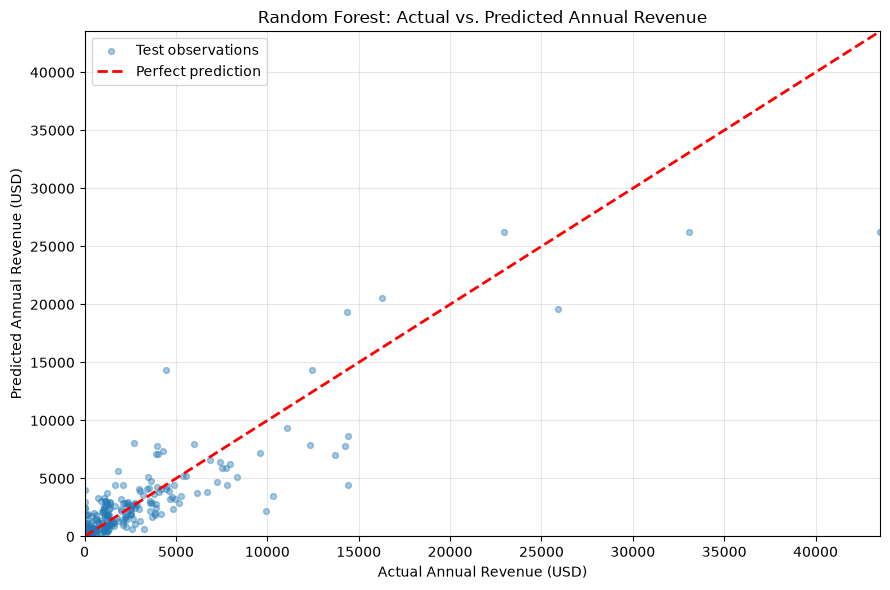

In [90]:
# Generating predictions from the saved pipeline
y_pred = reloaded_pipeline.predict(X_test)

# Establish equal axis limits for comparison
max_value = max(y_test.max(), y_pred.max())

plt.figure(figsize=(9, 6))

# Actual vs predicted revenue
plt.scatter(
    y_test,
    y_pred,
    alpha=0.4,
    s=18,
    label="Test observations"
)

# Perfect-prediction reference line
plt.plot(
    [0, max_value],
    [0, max_value],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

plt.xlabel("Actual Annual Revenue (USD)")
plt.ylabel("Predicted Annual Revenue (USD)")
plt.title("Random Forest: Actual vs. Predicted Annual Revenue")
plt.xlim(0, max_value)
plt.ylim(0, max_value)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Interpretation of the visualization
- Many observations cluster at lower revenues near the perfect-prediction line, although the scale and overlapping points make small errors difficult to assess visually.
- Larger deviations occur at higher revenues, with examples of both overestimation and underestimation. The highest-revenue test observation, around $43,500, is predicted at approximately $26,200, showing substantial underestimation.
- This pattern is consistent with the right-skewed revenue distribution: good aggregate performance can coexist with large errors for individual high-revenue systems.
- The verified saved forest has test R² of 0.8323, RMSE of approximately $726.13, and MAE of $149.77. These aggregate metrics complement the plot; they do not imply uniformly accurate predictions across revenue levels.

## 9.5 Training split exportation

In [91]:
api_dir = model_path.parent

if not api_dir.is_dir():
    raise FileNotFoundError(f"API directory not found: {api_dir}")

# Combining original training features with the target
training_data = X_train.copy()
training_data["wp_revenue_USD"] = y_train

# Saving the original unprocessed training observations
training_data_path = api_dir / "data" / "training_data.csv"
training_data.to_csv(training_data_path, index=False)

# Saving the reserved, unprocessed labeled observations separately
retraining_batch_path = api_dir / "data" / "retraining_batch.csv"
retraining_batch.to_csv(retraining_batch_path, index=False)

print(f"Training dataset saved to: {training_data_path}")
print(f"Dataset shape: {training_data.shape}")
print(f"Retraining batch saved to: {retraining_batch_path}")
print(f"Reserved retraining observations: {len(retraining_batch)}")

Training dataset saved to: c:\Users\nsleo\dev\linear_regression_model\summative\API\data\training_data.csv
Dataset shape: (9265, 9)
Retraining batch saved to: c:\Users\nsleo\dev\linear_regression_model\summative\API\data\retraining_batch.csv
Reserved retraining observations: 300
